# Logistic Regression
Owner: Anupama Singh

Predicts the 0/1 label (1 = the student grew more than the control group's average). This is the baseline model reported in the paper (Table 1).

## 1. Setup and data
Same data as the paper and as the rest of the team: 706 labeled students with no missing values, the paper's 16 features, two targets. The folds are identical to Megha's Random Forest and XGBoost notebooks.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import GroupKFold, cross_val_score
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import roc_auc_score, average_precision_score, accuracy_score, mean_absolute_error
from sklearn.linear_model import LogisticRegression
# Data: local copy in data/ if present, otherwise download from the ECRI repository
LOCAL = Path("../data")
URL = "https://raw.githubusercontent.com/ecri-data/ECRI-Dataset/main/ECRI"
src = LOCAL if (LOCAL / "ECRIDataSet.csv").exists() else URL

# Outputs: the repo's results/ folder when run locally, ./results in Colab
RESULTS = Path("../results") if Path("../results").exists() else Path("results")
RESULTS.mkdir(exist_ok=True)

# The paper's 16 features (Table 3) and the two Woodcock targets
FEATURES = ["Gender", "Tx", "Age1b", "Tier2_N", "grp_rate", "rcmistot", "gnrl_fid",
            "TKPctCrct", "NWFcls", "NWFwrc", "ORFwc", "SAwrS", "SAsrS", "SAtoS",
            "RMwidRS", "RMwdaRS"]
TARGETS = {"Word Identification": "RMwidRS", "Word Attack": "RMwdaRS"}

df = pd.read_csv(f"{src}/ECRIDataSet.csv")
raw = pd.read_csv(f"{src}/ECRIRawData.csv", low_memory=False)

# Spring scores are used ONLY to compute the gain (regression target), never as features
spring = raw[raw["Time"] == 2.0].set_index("StuID")[list(TARGETS.values())].add_suffix("_spring")

# Labeled students with no missing feature values, as in the paper (706 students)
data = (df[df["RMwidRS_target"].notna()]
        .dropna(subset=FEATURES)
        .join(spring, on="StuID")
        .reset_index(drop=True))
for score in TARGETS.values():
    data[f"{score}_gain"] = data[f"{score}_spring"] - data[score]

X = data[FEATURES]
print(f"Students: {len(data)} | Schools: {data['SchlID'].nunique()} | Features: {len(FEATURES)}")

Students: 706 | Schools: 42 | Features: 16


## 2. The model
Features are standardized (mean 0, standard deviation 1) inside each training fold, then a Logistic Regression estimates the probability of label 1. No settings are tuned.

In [2]:
MODEL_NAME = "Logistic Regression"
KIND = "classifier"


def build_model(setting=None):
    return make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000))

## 3. 5-fold cross-validation
- **School split (main):** `GroupKFold(5)` on `SchlID`. Every school sits in exactly one test fold, so each student is scored by a model that never saw their school.
- **Student split:** `GroupKFold(5)` on `StuID`, so a school can appear in both training and test.

Each round trains on 4 folds (about 565 students) and predicts the 5th (about 141). The prediction for every student is saved so the evaluation notebook can compute all metrics and curves.

In [3]:
SPLITS = {"school": "SchlID", "student": "StuID"}


def cross_validate(score, split):
    """5-fold grouped cross-validation. Returns one row per student with the out-of-fold prediction."""
    groups = data[SPLITS[split]]
    y = data[f"{score}_target"] if KIND == "classifier" else data[f"{score}_gain"]
    rows = []
    for fold, (train_idx, test_idx) in enumerate(GroupKFold(n_splits=5).split(X, y, groups), start=1):
        setting = None   # nothing to tune
        model = build_model(setting).fit(X.iloc[train_idx], y.iloc[train_idx])
        test = data.iloc[test_idx]
        prediction = model.predict_proba(test[FEATURES])[:, 1]    # probability of label 1
        pred_label = (prediction >= 0.5).astype(int)
        rows.append(pd.DataFrame({
            "split": split, "target": score, "model": MODEL_NAME, "fold": fold,
            "StuID": test["StuID"].values, "SchlID": test["SchlID"].values, "setting": setting,
            "true_label": test[f"{score}_target"].astype(int).values,
            "true_gain": test[f"{score}_gain"].values,
            "score": prediction,          # probability of label 1
            "pred_label": pred_label,
        }))
    return pd.concat(rows, ignore_index=True)


predictions = pd.concat([cross_validate(score, split)
                         for split in SPLITS for score in TARGETS.values()], ignore_index=True)
print("Predictions:", len(predictions), "rows (706 students x 2 targets x 2 splits)")

Predictions: 2824 rows (706 students x 2 targets x 2 splits)


## 4. Quick summary
Mean over the 5 folds. The full set of metrics and curves (precision, recall, ROC and PR curves, squared error) is in `anupama_baseline_evaluation.ipynb`.

In [4]:
rows = []
for (split, score, fold), g in predictions.groupby(["split", "target", "fold"]):
    row = {"split": split, "target": score, "fold": fold,
           "ROC AUC": roc_auc_score(g["true_label"], g["score"]),
           "PR-AUC": average_precision_score(g["true_label"], g["score"]),
           "Accuracy": accuracy_score(g["true_label"], g["pred_label"])}
    rows.append(row)
fold_results = pd.DataFrame(rows)

summary = (fold_results.drop(columns="fold").groupby(["split", "target"])
           .agg(["mean", "std"]).round(3)
           .rename(index={v: k for k, v in TARGETS.items()}, level=1))
summary

ROC AUC        PR-AUC        Accuracy       
                               mean    std   mean    std     mean    std
split   target                                                          
school  Word Attack           0.614  0.039  0.694  0.078    0.611  0.063
        Word Identification   0.671  0.057  0.684  0.047    0.640  0.052
student Word Attack           0.634  0.031  0.707  0.042    0.616  0.046
        Word Identification   0.667  0.069  0.688  0.090    0.637  0.068

## 5. Which features matter
Coefficients of the standardized features, fitted on all 706 students. Positive = more likely to show high growth.

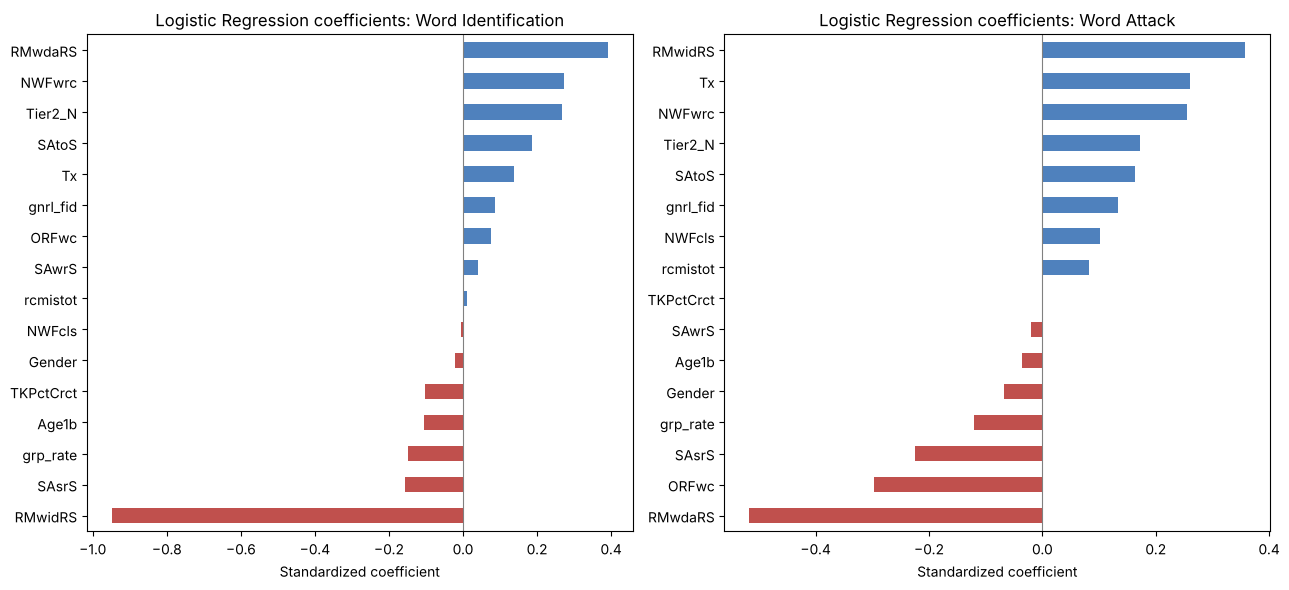

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(13, 6))
for ax, (target_name, score) in zip(axes, TARGETS.items()):
    fitted = build_model().fit(X, data[f"{score}_target"])
    coefs = pd.Series(fitted[-1].coef_[0], index=FEATURES).sort_values()
    coefs.plot.barh(ax=ax, color=["#c0504d" if v < 0 else "#4f81bd" for v in coefs])
    ax.axvline(0, color="gray", linewidth=0.8)
    ax.set_title(f"Logistic Regression coefficients: {target_name}")
    ax.set_xlabel("Standardized coefficient")
plt.tight_layout()
plt.savefig(RESULTS / "logistic_regression_coefficients.png", dpi=150)
plt.show()

## Save the results

In [6]:
predictions.to_csv(RESULTS / "logistic_regression_cv_predictions.csv", index=False)
fold_results.to_csv(RESULTS / "logistic_regression_cv_fold_results.csv", index=False)
print(f"Saved logistic_regression_cv_predictions.csv and logistic_regression_cv_fold_results.csv to {RESULTS}/")

Saved logistic_regression_cv_predictions.csv and logistic_regression_cv_fold_results.csv to ../results/
